# Replay one experimental game

This notebook replays one Choi 2020 game and shows:

- the replay setup in separate stages
- the actions printed per step
- the directed ownership graph after each recorded state
- the density evolution across the replay


## Imports


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scienceplots

project_root = Path.cwd()
if not (project_root / "network_creation").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from network_creation.data.choi_2020 import (build_replay_simulator,
                                             list_choi_2020_configs,
                                             load_choi_2020_normalized_data,
                                             run_choi_2020_replay_batch)
from network_creation.observers.action_print_observer import \
    ActionPrintObserver
from network_creation.observers.density_observer import DensityObserver
from network_creation.observers.state_history_observer import \
    StateHistoryObserver
from network_creation.plotting.episode_series import \
    plot_episode_series_observer
from network_creation.plotting.ownership_history import \
    build_circle_layout, plot_ownership_history


In [2]:
plt.style.use(style="science")

In [3]:
fixed_layout = build_circle_layout(n_nodes=6)


## Replay data


In [4]:
data_root = project_root / "data/choi_2020/raw"
available_configs = list_choi_2020_configs(data_root)
available_configs[:5]

(Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=2, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')),
 Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=3, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')),
 Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=4, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')),
 Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=5, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')),
 Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=6, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv')))

## Observer settings


In [5]:
action_printer = ActionPrintObserver(observation_frequency=1, print_empty_steps=False)
density_observer = DensityObserver(observation_frequency=1, aggregations=())
state_history_observer = StateHistoryObserver(observation_frequency=1, keep_runs=False)

(
    action_printer.__class__.__name__,
    density_observer.__class__.__name__,
    state_history_observer.__class__.__name__,
)

('ActionPrintObserver', 'DensityObserver', 'StateHistoryObserver')

## Build the replay simulator


In [6]:
config = available_configs[0]
config

Choi2020ReplayConfig(group_size=10, session_id=1, group_id=1, round_id=2, source_path=PosixPath('/home/hdahmou/Network_creation/data/choi_2020/raw/Linking_10_1/data.csv'))

In [7]:
max_steps = load_choi_2020_normalized_data(config).max_step
max_steps

359

In [8]:
simulator = build_replay_simulator(
    config=config,
    observers=(action_printer, density_observer, state_history_observer),
    max_steps=max_steps,
)

fixed_layout = build_circle_layout(simulator.n_agents)
(simulator.mode, simulator.max_steps, simulator.n_agents)

(<SchedulingMode.SIMULTANEOUS: 'SIMULTANEOUS'>, 359, 10)

## Run the replay


In [9]:
simulator.run(n_episodes=1)

(
    simulator.n_completed_episodes,
    state_history_observer.steps[-1],
    density_observer.steps[-1],
)


step 6
  8: ADD->2

step 7
  2: ADD->4
  3: ADD->5
  6: ADD->4
  8: ADD->3, ADD->4

step 8
  1: ADD->5
  2: ADD->7

step 9
  5: ADD->7
  7: ADD->0
  8: ADD->6
  9: ADD->8

step 10
  8: ADD->0

step 11
  4: ADD->8
  6: DELETE->4

step 12
  1: ADD->4

step 13
  1: DELETE->5
  7: DELETE->0

step 14
  2: DELETE->7, ADD->8

step 15
  2: DELETE->8
  5: ADD->8

step 16
  2: ADD->9

step 17
  5: DELETE->7

step 18
  2: DELETE->9
  3: DELETE->5
  8: ADD->7

step 19
  1: ADD->8
  2: DELETE->4

step 20
  1: DELETE->4
  2: ADD->7

step 22
  2: DELETE->7

step 23
  2: ADD->6

step 24
  9: ADD->4, DELETE->8

step 26
  2: DELETE->6

step 28
  8: ADD->9

step 31
  3: ADD->7
  5: ADD->9

step 32
  3: DELETE->7
  5: DELETE->8

step 34
  5: ADD->8

step 35
  3: ADD->8
  5: DELETE->9

step 36
  2: ADD->5

step 37
  2: DELETE->5

step 39
  2: ADD->1
  3: DELETE->8

step 40
  2: DELETE->1

step 41
  2: ADD->0
  8: DELETE->4

step 42
  2: DELETE->0

step 43
  2: ADD->7
  5: ADD->2

step 44
  2: DELETE->7
  

(1, np.int64(359), np.int64(359))

## Directed ownership graph after each recorded state


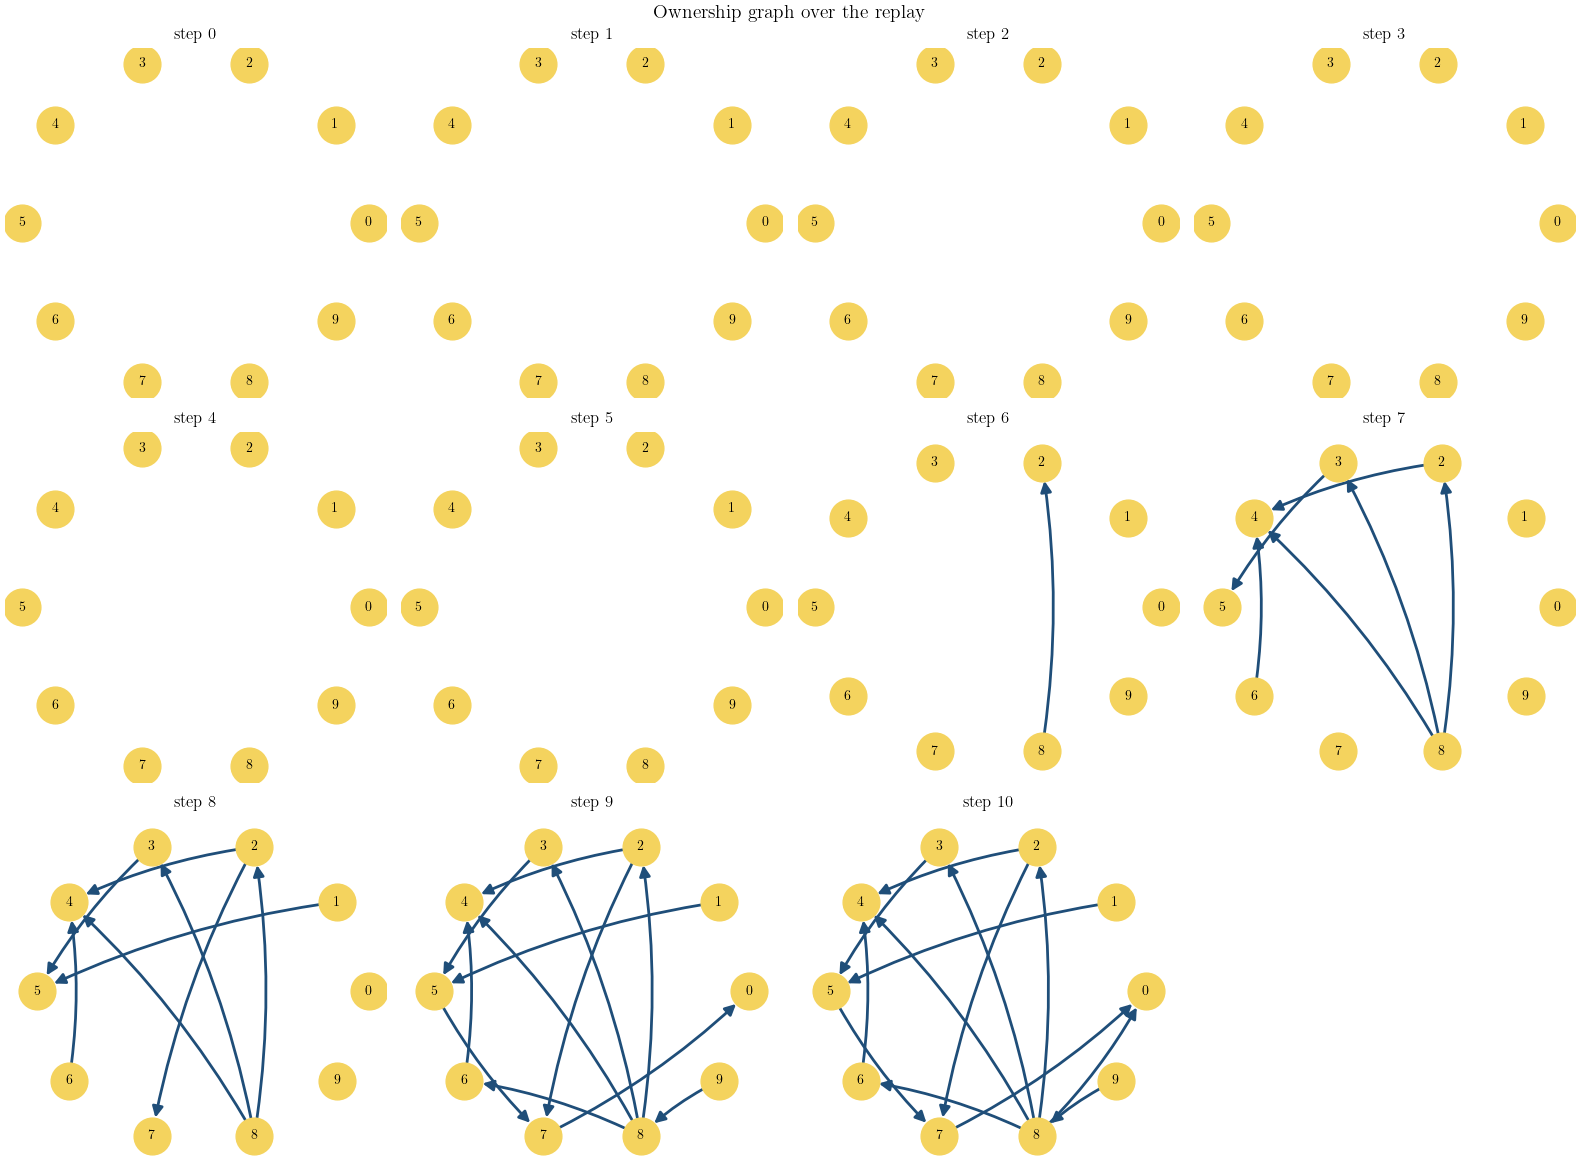

In [10]:
plot_mask = state_history_observer.steps <= 10
plot_ownership_history(
    steps=state_history_observer.steps[plot_mask],
    ownership_matrices=state_history_observer.ownership_matrices[plot_mask],
    layout=fixed_layout,
    figure_title="Ownership graph over the replay",
    max_cols=4,
)
plt.show()


## Density across the replay


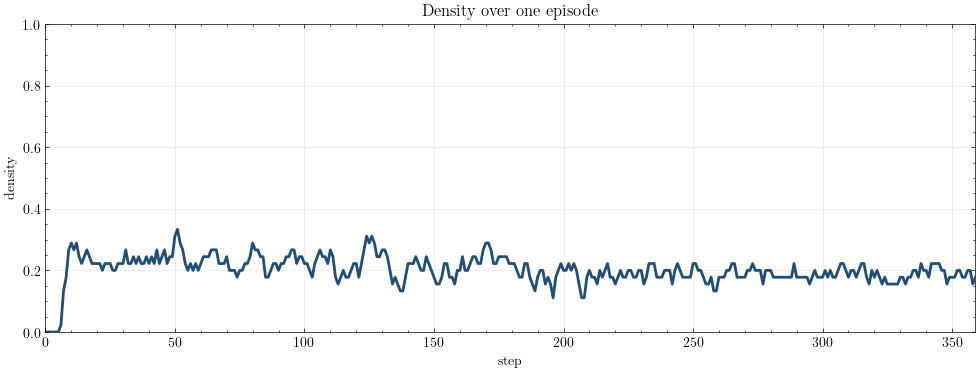

In [11]:
figure, axis = plt.subplots(figsize=(12, 4))
plot_episode_series_observer(observer=density_observer, ax=axis)
plt.show()

## Aggregate density for group size 10


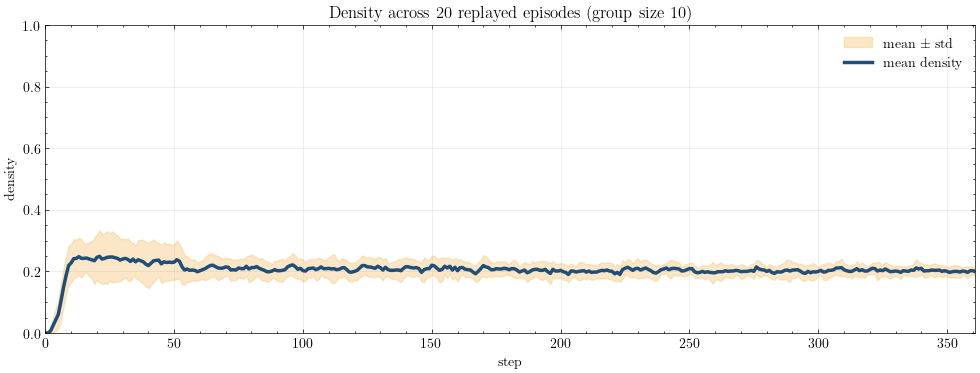

In [12]:
group_size = 10
group_configs = tuple(
    replay_config
    for replay_config in available_configs
    if replay_config.group_size == group_size
)
aggregate_density_observer = DensityObserver(
    observation_frequency=1,
    aggregations=("mean", "std"),
)
run_choi_2020_replay_batch(
    configs=group_configs,
    observers=(aggregate_density_observer,),
    max_steps=361,
)

figure, axis = plt.subplots(figsize=(12, 4))
plot_episode_series_observer(observer=aggregate_density_observer, ax=axis, show_runs=True)
axis.set_title(
    f"Density across {aggregate_density_observer.n_episodes} replayed episodes "
    f"(group size {group_size})"
)
plt.show()
